In [1]:
import os

files = [
    "X_train_selected.csv",
    "X_test_selected.csv",
    "y_train_selected.csv",
    "y_test_selected.csv",
    "selected_features.csv"
]

for file in files:
    print(file, "→", os.path.exists(file))

X_train_selected.csv → False
X_test_selected.csv → False
y_train_selected.csv → False
y_test_selected.csv → False
selected_features.csv → False


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
pd.set_option('display.max_columns',None)

In [4]:
X_train = pd.read_csv(r"../DATA/ModelData/X_train_selected.csv")
X_test = pd.read_csv(r"../DATA/ModelData/X_test_selected.csv")

y_train = pd.read_csv(r"../DATA/ModelData/y_train_selected.csv").squeeze()
y_test = pd.read_csv(r"../DATA/ModelData/y_test_selected.csv").squeeze()

In [5]:
X_train.head()

,remainder__num_lab_procedures,remainder__num_medications,remainder__time_in_hospital,remainder__discharge_disposition_id,remainder__number_diagnoses,remainder__num_procedures,remainder__age,remainder__total_previous_visits,remainder__number_inpatient,remainder__admission_type_id,remainder__num_unique_diagnosis_categories,remainder__admission_source_id,remainder__total_medications,remainder__weight,categorical__diag_3_category_Circulatory,categorical__diag_3_category_Endocrine,categorical__diag_2_category_Circulatory,categorical__gender_Male,categorical__gender_Female,categorical__diag_1_category_Circulatory,remainder__number_outpatient,remainder__has_previous_visits,categorical__diag_2_category_Endocrine,remainder__number_emergency,categorical__age_group_Middle_Aged,categorical__race_Caucasian,categorical__stay_category_Medium,categorical__age_group_Senior,categorical__race_AfricanAmerican,categorical__medical_specialty_Unknown,categorical__medical_specialty_grouped_Unknown,categorical__diag_2_category_Respiratory,categorical__insulin_Steady,categorical__diag_1_category_Endocrine,categorical__diag_1_category_Respiratory,categorical__diag_1_category_Digestive,categorical__diag_2_category_Genitourinary,categorical__stay_category_Short,categorical__insulin_No,categorical__diag_3_category_Respiratory,categorical__stay_category_Long,categorical__glipizide_No,categorical__diag_1_category_Symptoms,categorical__diag_3_category_Genitourinary,categorical__metformin_No,categorical__medical_specialty_grouped_InternalMedicine,categorical__glipizide_Steady,categorical__metformin_Steady,categorical__diag_1_category_Injury,categorical__medical_specialty_InternalMedicine,categorical__age_group_Adult,categorical__glyburide_No,remainder__num_medications_changed,categorical__change_Ch,categorical__change_No,categorical__glyburide_Steady,categorical__diag_1_category_Genitourinary,categorical__diag_3_category_Symptoms,categorical__insulin_Down,categorical__insulin_Up,categorical__diag_2_category_Symptoms,categorical__pioglitazone_No,categorical__medical_specialty_grouped_Family/GeneralPractice,categorical__medical_specialty_Family/GeneralPractice,categorical__diag_3_category_V-code,remainder__has_medication_change,categorical__pioglitazone_Steady,categorical__diag_3_category_Digestive,categorical__rosiglitazone_No,categorical__diag_2_category_Digestive,categorical__rosiglitazone_Steady,categorical__diag_2_category_Skin,categorical__medical_specialty_Emergency/Trauma,categorical__medical_specialty_grouped_Emergency/Trauma,categorical__glimepiride_No,categorical__diag_3_category_Mental,categorical__diag_1_category_Musculoskeletal,categorical__glimepiride_Steady,categorical__diag_1_category_Infectious,categorical__diag_2_category_Blood,categorical__medical_specialty_grouped_Cardiology,categorical__medical_specialty_Cardiology,categorical__diag_3_category_Skin,categorical__diag_3_category_Blood,categorical__diag_1_category_Skin,categorical__diag_1_category_Neoplasms,categorical__diag_2_category_Mental,categorical__diag_2_category_Neoplasms,categorical__diag_2_category_Injury,categorical__diabetesMed_No,categorical__diag_2_category_Infectious,categorical__diag_3_category_Nervous,categorical__medical_specialty_Surgery-General,categorical__medical_specialty_grouped_Surgery-General,categorical__diag_3_category_Musculoskeletal,categorical__diag_3_category_Injury,categorical__diag_3_category_Infectious,categorical__diag_3_category_Neoplasms,categorical__diabetesMed_Yes,categorical__diag_2_category_V-code,categorical__diag_2_category_Musculoskeletal,categorical__diag_1_category_Mental,categorical__diag_2_category_Nervous,categorical__diag_1_category_Blood,categorical__medical_specialty_grouped_Nephrology,categorical__medical_specialty_Nephrology,categorical__diag_3_category_E-code,categorical__race_Other,categorical__diag_1_category_Nervous,categorical__diag_1_category_V-code,categorical__repaglinide_No,categorical__repaglinide_Steady,categorical__age_group_

In [6]:
from sklearn.linear_model import LogisticRegression

In [7]:
from sklearn.metrics import accuracy_score

### Check the Data

In [8]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (75028, 123)
X_test: (18758, 123)
y_train: (75028,)
y_test: (18758,)


In [9]:
print("\nTarget distribution:")
print(y_train.value_counts())


Target distribution:
readmitted
NO     39924
>30    26618
<30     8486
Name: count, dtype: int64


In [10]:
print(y_test.value_counts())

readmitted
NO     9981
>30    6655
<30    2122
Name: count, dtype: int64


### Import StandardScaler

In [11]:
from sklearn.preprocessing import StandardScaler

### Create the scaler

In [12]:
scaler = StandardScaler()

### Scale training and test data

In [13]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Train the Logistic Regression baseline

In [14]:
logistic_model_scaled = LogisticRegression(
    max_iter=10000,
    random_state=42
)

### Train the model

In [15]:
logistic_model_scaled.fit(
    X_train_scaled,
    y_train
)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,10000
,multi_class,'deprecated'


In [16]:
y_pred = logistic_model_scaled.predict(X_test_scaled)

In [17]:
print("First 20 predictions:")
print(y_pred[:20])

First 20 predictions:
['NO' 'NO' '>30' 'NO' 'NO' 'NO' '>30' '>30' 'NO' 'NO' '>30' 'NO' 'NO' 'NO'
 '>30' '>30' 'NO' 'NO' 'NO' '>30']


### Evaluate the Logistic Regression baseline

In [18]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.5692504531399936


In [19]:
print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 56.93%


### Classification report

In [20]:
from sklearn.metrics import classification_report

In [21]:
print(
    classification_report(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

         <30       0.53      0.02      0.03      2122
         >30       0.49      0.33      0.40      6655
          NO       0.59      0.85      0.70      9981

    accuracy                           0.57     18758
   macro avg       0.54      0.40      0.37     18758
weighted avg       0.55      0.57      0.52     18758



### Confusion Matrix

In [22]:
from sklearn.metrics import confusion_matrix

In [23]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print(cm)

[[  34  735 1353]
 [  15 2206 4434]
 [  15 1528 8438]]


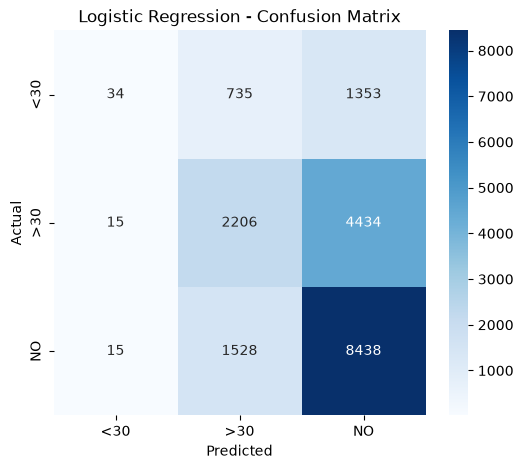

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=logistic_model_scaled.classes_,
    yticklabels=logistic_model_scaled.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")

plt.show()

### End

### Decision Tree

In [25]:
from sklearn.tree import DecisionTreeClassifier

In [26]:
decision_tree = DecisionTreeClassifier(
    random_state=42
)

In [27]:
decision_tree.fit(
    X_train,
    y_train
)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [44]:
y_pred_dt = decision_tree.predict(X_test)

In [48]:
y_pred_dt

array(['NO', 'NO', 'NO', ..., 'NO', '>30', 'NO'],
      shape=(18758,), dtype=object)

### Calculate accuracy

In [49]:
accuracy_dt = accuracy_score(
    y_test,
    y_pred_dt
)

print(f"Decision Tree Accuracy: {accuracy_dt * 100:.2f}%")

Decision Tree Accuracy: 47.31%


### Classification report

In [50]:
print(
    classification_report(
        y_test,
        y_pred_dt
    )
)

              precision    recall  f1-score   support

         <30       0.16      0.16      0.16      2122
         >30       0.40      0.41      0.40      6655
          NO       0.59      0.58      0.59      9981

    accuracy                           0.47     18758
   macro avg       0.38      0.38      0.38     18758
weighted avg       0.48      0.47      0.47     18758



### Confusion Matrix

In [51]:
cm_dt = confusion_matrix(
    y_test,
    y_pred_dt
)

print(cm_dt)

[[ 339  923  860]
 [ 805 2721 3129]
 [ 997 3169 5815]]


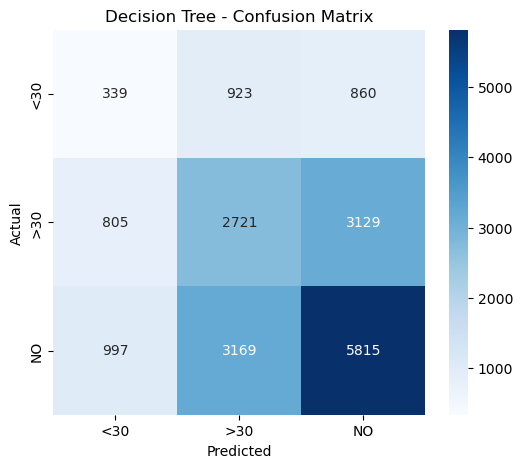

In [52]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=decision_tree.classes_,
    yticklabels=decision_tree.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree - Confusion Matrix")

plt.show()

### End

### Random Forest

In [53]:
from sklearn.ensemble import RandomForestClassifier

### Create the model

In [55]:
random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

### Train the model

In [56]:
random_forest.fit(
    X_train,
    y_train
)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


### Make predictions

In [57]:
y_pred_rf = random_forest.predict(X_test)

In [58]:
y_pred_rf

array(['NO', 'NO', 'NO', ..., 'NO', 'NO', 'NO'],
      shape=(18758,), dtype=object)

### Calculate accuracy

In [59]:
accuracy_rf = accuracy_score(
    y_test,
    y_pred_rf
)

print(f"Random Forest Accuracy: {accuracy_rf * 100:.2f}%")

Random Forest Accuracy: 57.47%


### Classification report

In [60]:
print(
    classification_report(
        y_test,
        y_pred_rf
    )
)

              precision    recall  f1-score   support

         <30       0.43      0.02      0.03      2122
         >30       0.49      0.39      0.43      6655
          NO       0.61      0.82      0.70      9981

    accuracy                           0.57     18758
   macro avg       0.51      0.41      0.39     18758
weighted avg       0.55      0.57      0.53     18758



### Confusion matrix

In [61]:
cm_rf = confusion_matrix(
    y_test,
    y_pred_rf
)

print(cm_rf)

[[  34  858 1230]
 [  32 2589 4034]
 [  13 1810 8158]]


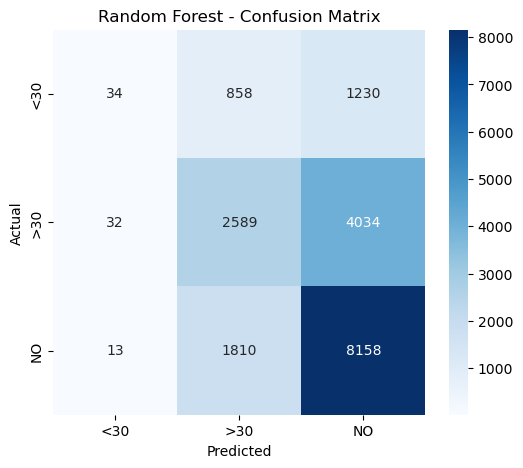

In [62]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=random_forest.classes_,
    yticklabels=random_forest.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest - Confusion Matrix")

plt.show()

### End

### Gradient Boosting

In [63]:
from sklearn.ensemble import GradientBoostingClassifier

### Create the model

In [64]:
gradient_boosting = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

### Train

In [65]:
gradient_boosting.fit(
    X_train,
    y_train
)

,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


### Predict

In [67]:
y_pred_gb = gradient_boosting.predict(X_test)

In [68]:
y_pred_gb

array(['NO', 'NO', 'NO', ..., 'NO', 'NO', 'NO'],
      shape=(18758,), dtype=object)

### Accuracy

In [69]:
accuracy_gb = accuracy_score(
    y_test,
    y_pred_gb
)

print(
    f"Gradient Boosting Accuracy: {accuracy_gb * 100:.2f}%"
)

Gradient Boosting Accuracy: 57.99%


### Classification report

In [70]:
print(
    classification_report(
        y_test,
        y_pred_gb
    )
)

              precision    recall  f1-score   support

         <30       0.49      0.02      0.04      2122
         >30       0.50      0.36      0.42      6655
          NO       0.61      0.85      0.71      9981

    accuracy                           0.58     18758
   macro avg       0.53      0.41      0.39     18758
weighted avg       0.56      0.58      0.53     18758



### Confusion matrix

In [71]:
cm_gb = confusion_matrix(
    y_test,
    y_pred_gb
)

print(cm_gb)

[[  43  823 1256]
 [  30 2388 4237]
 [  14 1520 8447]]


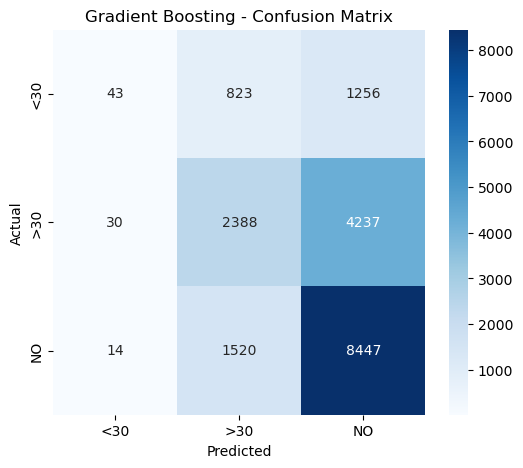

In [72]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_gb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=gradient_boosting.classes_,
    yticklabels=gradient_boosting.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Gradient Boosting - Confusion Matrix")

plt.show()

### End

### Compare the baseline models

### Import the metrics

In [74]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

### Create a helper function

In [75]:
def evaluate_model(model_name, y_true, y_pred):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        )
    }

### Evaluate all four models

In [77]:
results = []

results.append(
    evaluate_model(
        "Logistic Regression",
        y_test,
        y_pred
    )
)

results.append(
    evaluate_model(
        "Decision Tree",
        y_test,
        y_pred_dt
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        y_pred_rf
    )
)

results.append(
    evaluate_model(
        "Gradient Boosting",
        y_test,
        y_pred_gb
    )
)

### Create the comparison table

In [78]:
results_df = pd.DataFrame(results)

print(results_df)

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.569091   0.549864  0.569091  0.515001
1        Decision Tree  0.473131   0.475204  0.473131  0.474122
2        Random Forest  0.574741   0.546822  0.574741  0.528677
3    Gradient Boosting  0.579913   0.557415  0.579913  0.529008


In [79]:
results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

print(results_df.to_string(index=False))

              Model  Accuracy  Precision   Recall  F1 Score
  Gradient Boosting  0.579913   0.557415 0.579913  0.529008
      Random Forest  0.574741   0.546822 0.574741  0.528677
Logistic Regression  0.569091   0.549864 0.569091  0.515001
      Decision Tree  0.473131   0.475204 0.473131  0.474122


### Evaluation Metrics — Step 1: Detailed class-level evaluation

### Classification report for Logistic Regression

In [80]:
print("Logistic Regression")
print(
    classification_report(
        y_test,
        y_pred
    )
)

Logistic Regression
              precision    recall  f1-score   support

         <30       0.52      0.02      0.03      2122
         >30       0.49      0.33      0.40      6655
          NO       0.59      0.85      0.70      9981

    accuracy                           0.57     18758
   macro avg       0.54      0.40      0.37     18758
weighted avg       0.55      0.57      0.52     18758



### Focus specifically on <30

In [81]:
from sklearn.metrics import precision_recall_fscore_support

precision, recall, f1, support = precision_recall_fscore_support(
    y_test,
    y_pred,
    labels=["<30"],
    zero_division=0
)

print("Class: <30")
print("Precision:", precision[0])
print("Recall:", recall[0])
print("F1 Score:", f1[0])
print("Support:", support[0])

Class: <30
Precision: 0.5238095238095238
Recall: 0.015551366635249765
F1 Score: 0.030205949656750573
Support: 2122


### Do the same for all models

We can compare the <30 performance:

In [82]:
models_predictions = {
    "Logistic Regression": y_pred,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "Gradient Boosting": y_pred_gb
}

evaluation_results = []

for model_name, predictions in models_predictions.items():

    precision, recall, f1, support = precision_recall_fscore_support(
        y_test,
        predictions,
        labels=["<30"],
        zero_division=0
    )

    evaluation_results.append({
        "Model": model_name,
        "Precision_<30": precision[0],
        "Recall_<30": recall[0],
        "F1_<30": f1[0],
        "Support_<30": support[0]
    })

In [83]:
evaluation_df = pd.DataFrame(evaluation_results)

print(
    evaluation_df.to_string(index=False)
)

              Model  Precision_<30  Recall_<30   F1_<30  Support_<30
Logistic Regression       0.523810    0.015551 0.030206         2122
      Decision Tree       0.158337    0.159755 0.159043         2122
      Random Forest       0.430380    0.016023 0.030895         2122
  Gradient Boosting       0.494253    0.020264 0.038932         2122


In [116]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(logistic_model_scaled, "../models/logistic_regression.pkl")
joblib.dump(decision_tree, "../models/decision_tree.pkl")
joblib.dump(random_forest, "../models/random_forest.pkl")
joblib.dump(gradient_boosting, "../models/gradient_boosting.pkl")
joblib.dump(scaler, "../models/scaler.pkl")

['../models/scaler.pkl']